# Lecture 3 — Evaluation of Explanations and Trustworthy AI
## From explanation outputs to evidence about explanation quality

In the previous lecture, we focused on **generating explanations** using methods such as SHAP, LIME, Integrated Gradients, and Grad-CAM.

This lecture asks the next scientific question:

> **What evidence supports the claims we make from an explanation?**

Throughout the lecture we will use three recurring examples:

1. **Loan approval + SHAP** — local feature attribution.
2. **Pneumonia chest X-ray + Grad-CAM** — spatial explanation.
3. **Sensor anomaly monitoring** — explanation stability under small input changes.

### Central idea

> ## **Claim → property → test → evidence → scoped conclusion**


# Learning objectives

By the end of the lecture, you should be able to:

- explain **why XAI explanations need to be evaluated**;
- distinguish **plausibility** from **faithfulness**;
- explain why a “good explanation” is **multi-dimensional and context-dependent**;
- distinguish **functionally grounded, human-grounded, and application-grounded** evaluation;
- identify important explanation properties such as **faithfulness, stability, localisation, compactness, model sensitivity, and human utility**;
- choose an evaluation method that matches a specific claim;
- interpret evaluation results without making stronger claims than the evidence supports;
- explain how XAI evaluation fits within **Trustworthy AI**.


# 1. Why evaluate explanations?

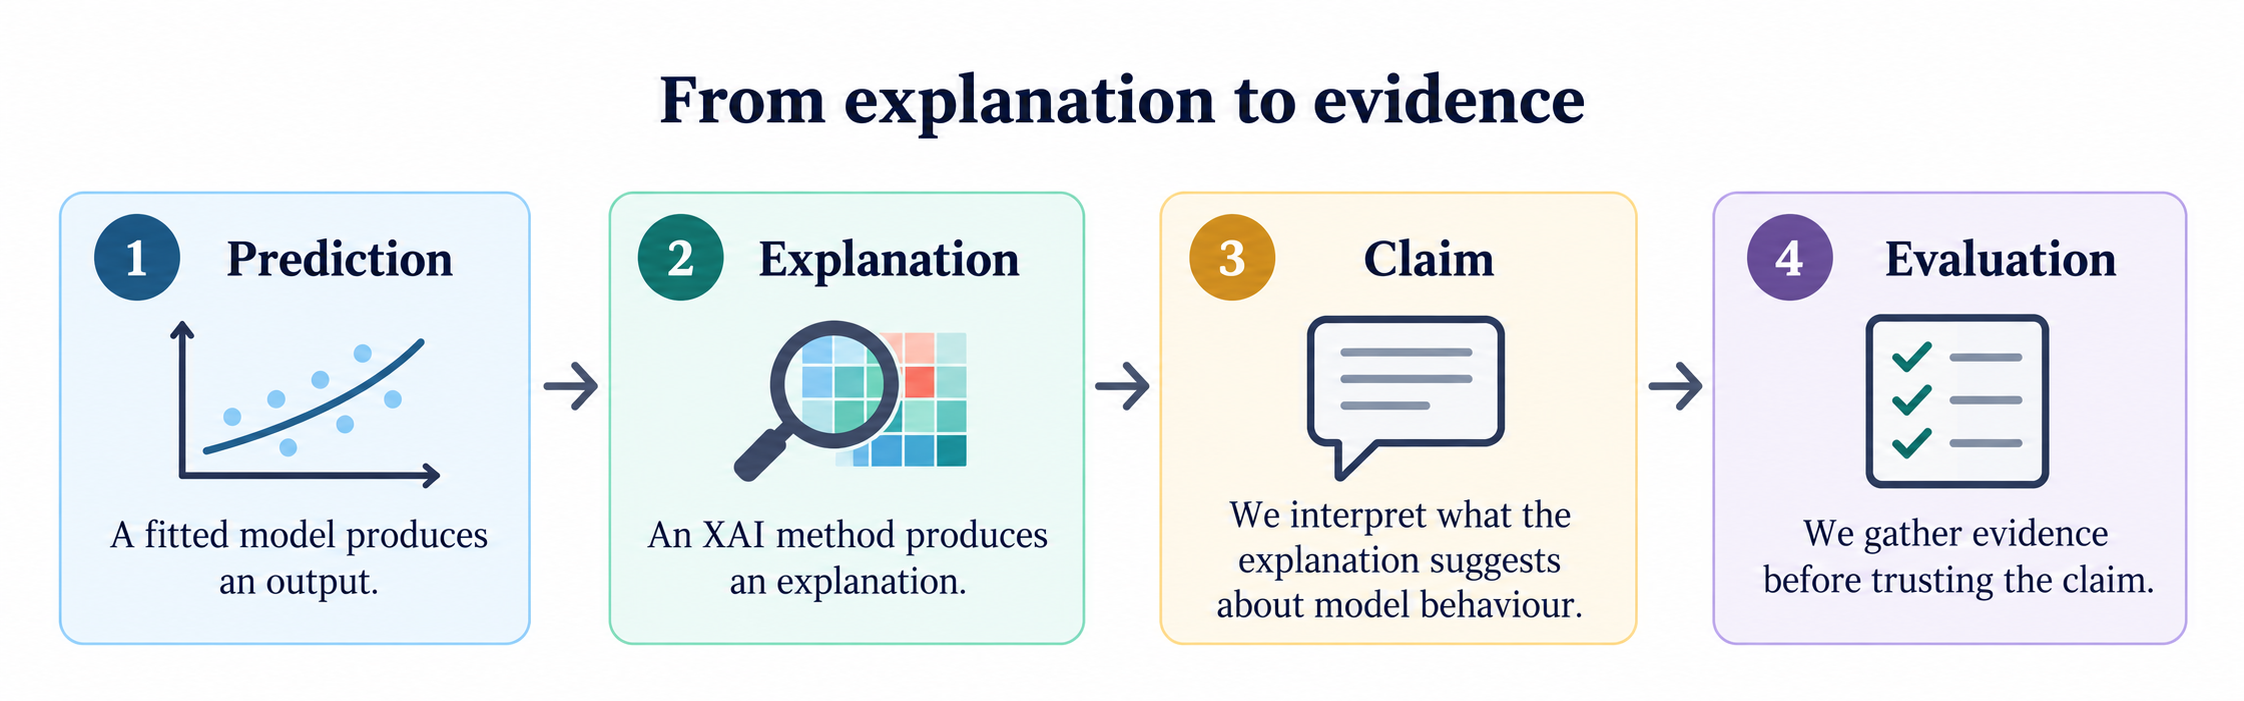

The figure above shows the key transition:

> **A model produces a prediction, an XAI method produces an explanation, we interpret that explanation as a claim about model behaviour, and evaluation asks what evidence supports that claim.**

Generating an explanation is only the first step.

The important transition is from **producing an explanation** to **making a claim about what that explanation means** — and then asking what evidence supports that claim.

Different explanation methods can produce different explanations for the same model prediction because they may rely on different assumptions, reference choices, or definitions of importance.

An explanation can also:

- look convincing while poorly reflecting the fitted model;
- change substantially after a small input change;
- depend strongly on the explainer configuration;
- align with human expectations without representing learned model behaviour;
- be technically correct but unhelpful to the intended user.

### Example — pneumonia chest X-ray

Suppose Grad-CAM highlights a region of the lung that appears medically plausible.

The heatmap may look convincing.

But several questions remain:

- Does the heatmap actually depend on what the model learned?
- Would a small, irrelevant change to the image produce a very different heatmap?
- Does the highlighted region align with a meaningful spatial reference?
- Does showing the heatmap help a radiologist make better decisions?

These are **different evaluation questions**, and each requires different evidence.

> **An explanation should not be accepted simply because it looks reasonable. The claims we make from it require evidence.**

Nauta et al. (2023) included 361 papers in their systematic review, of which **312 introduced XAI methods**. Their analysis treats explanation quality as **multi-faceted**: an explanation may perform well on one property, such as plausibility or compactness, while performing poorly on another, such as faithfulness or stability.

Therefore, instead of asking:

> **“Is this explanation good?”**

we should ask:

> **“Good in what sense, and what evidence supports that claim?”**

# 2. What is a “good explanation”?

There is no single universally accepted definition of a **good explanation**.

Explanation quality depends on:

- **what the explanation is intended to represent**;
- **which property we want to evaluate**;
- **who will use the explanation**;
- **what task the user is trying to perform**;
- **the application context**.

This means that an explanation may perform well in one respect and poorly in another.

For example, an explanation may be:

- easy for a person to understand, but poorly reflect the fitted model;
- faithful to the model, but unstable under small input changes;
- compact, but omit information that is important for the user's task.

> **Explanation quality is therefore multi-dimensional rather than a single “good/bad” property.**

## The Co-12 framework

Nauta et al. (2023) organise explanation quality into **12 conceptual properties**, referred to as the **Co-12 properties**.

### Content — what does the explanation say about the model or prediction?

- **Correctness** — does the explanation correctly reflect the behaviour of the model?
- **Completeness** — does the explanation capture the relevant information needed to account for the model behaviour being explained?
- **Consistency** — are identical or equivalent situations explained consistently?
- **Continuity** — do similar inputs with similar model behaviour receive similar explanations?
- **Contrastivity** — does the explanation distinguish the observed outcome from relevant alternatives?
- **Covariate complexity** — how complex are the features or concepts used in the explanation?

### Presentation — how is the explanation presented?

- **Compactness** — how concise is the explanation?
- **Composition** — how is the explanation structured and organised?
- **Confidence** — does the explanation communicate relevant uncertainty or confidence information?

### User — how does the explanation relate to the person using it?

- **Context** — is the explanation appropriate for the user's task and situation?
- **Coherence** — does the explanation fit with the user's relevant knowledge and expectations?
- **Controllability** — can the user interact with or influence the explanation process?

We will not study all twelve properties in detail.

Instead, this lecture focuses on a smaller set of evaluation questions that illustrate the main scientific ideas:

- **faithfulness / correctness**;
- **local stability / continuity**;
- **localisation**;
- **compactness**;
- **model sensitivity**;
- **human utility and performance**.

Some of these correspond closely to Co-12 properties, while others are common evaluation questions used more broadly in the XAI literature.

> **A good explanation is not defined by one metric. Its quality should be evaluated in relation to the properties required for its intended claim, user, task, and context.**

# 3. Plausibility is not faithfulness

A central distinction in XAI evaluation is between **plausibility** and **faithfulness**.

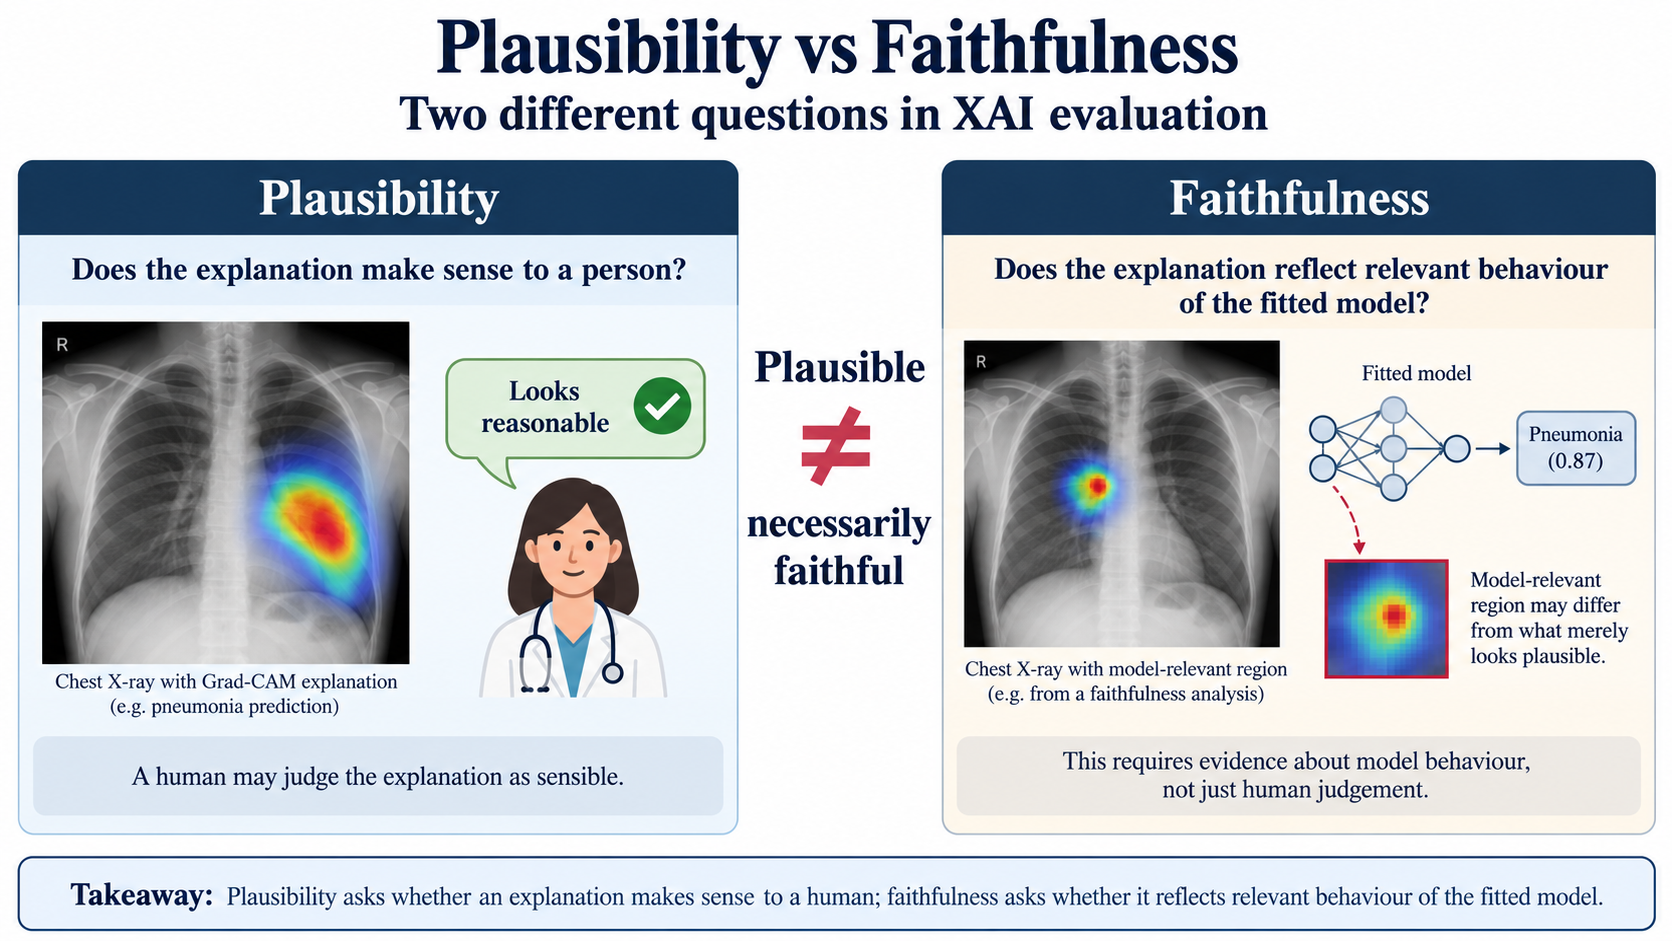

The figure illustrates the key distinction:

> **Plausibility asks whether an explanation makes sense to a person, while faithfulness asks whether it reflects relevant behaviour of the fitted model.**

## Plausibility

> **Does the explanation make sense to a person?**

Suppose a SHAP explanation for a loan prediction highlights:

- debt-to-income ratio;
- credit history;
- requested loan amount.

A domain expert may look at these features and say:

> “These factors make sense for this decision.”

This provides evidence of **plausibility**: the explanation is consistent with the person’s expectations or domain knowledge.

However, this does not yet tell us whether the explanation accurately reflects the behaviour of the fitted model.

## Faithfulness

> **Does the explanation reflect relevant behaviour of the fitted model?**

An explanation may look convincing to a person while still failing to represent how the fitted model behaves.

For example, a visually plausible saliency map may remain similar even after important learned model information has been disrupted.

Adebayo et al. (2018) demonstrated this problem using **model-parameter randomisation** and **data-randomisation** sanity checks for saliency methods.

Their results showed that visual plausibility alone is not sufficient evidence that an explanation is sensitive to what the model has learned.

> **A plausible explanation is not necessarily a faithful explanation.**

### Key distinction

- **Plausibility:** does the explanation make sense to a human?
- **Faithfulness:** does the explanation reflect relevant behaviour of the fitted model?

The two questions require different kinds of evidence.

# 4. What exactly are we evaluating?

Before selecting a metric, identify the **evaluation target**.

Sokol and Vogt (2024) argue that XAI systems should be evaluated compositionally and contextually rather than as one indivisible object.

A useful simplification is to distinguish three targets.

| Target | Main question | Example |
|---|---|---|
| **Explanation mechanism** | Does the method satisfy its algorithmic or formal properties? | Does SHAP reconstruct the explained model output? |
| **Explanation artefact** | Does the produced explanation have the property we claim? | Is a Grad-CAM heatmap stable or spatially aligned? |
| **Human–AI system** | Does the explanation help people perform the intended task? | Do radiologists make better decisions with the heatmap? |

These levels can fail independently.

A technically correct explanation mechanism can still produce:

- a confusing presentation;
- an unstable explanation;
- inappropriate human reliance;
- no improvement in task performance.

> **Always identify what component your evaluation result applies to.**


# 5. Three levels of XAI evaluation

Doshi-Velez and Kim (2017) distinguish three broad approaches to evaluate:

1. **functionally grounded evaluation**;
2. **human-grounded evaluation**;
3. **application-grounded evaluation**.

They differ mainly in the amount of **human involvement, task realism, and application specificity**.

These approaches are complementary rather than a ranking from “bad” to “good”.

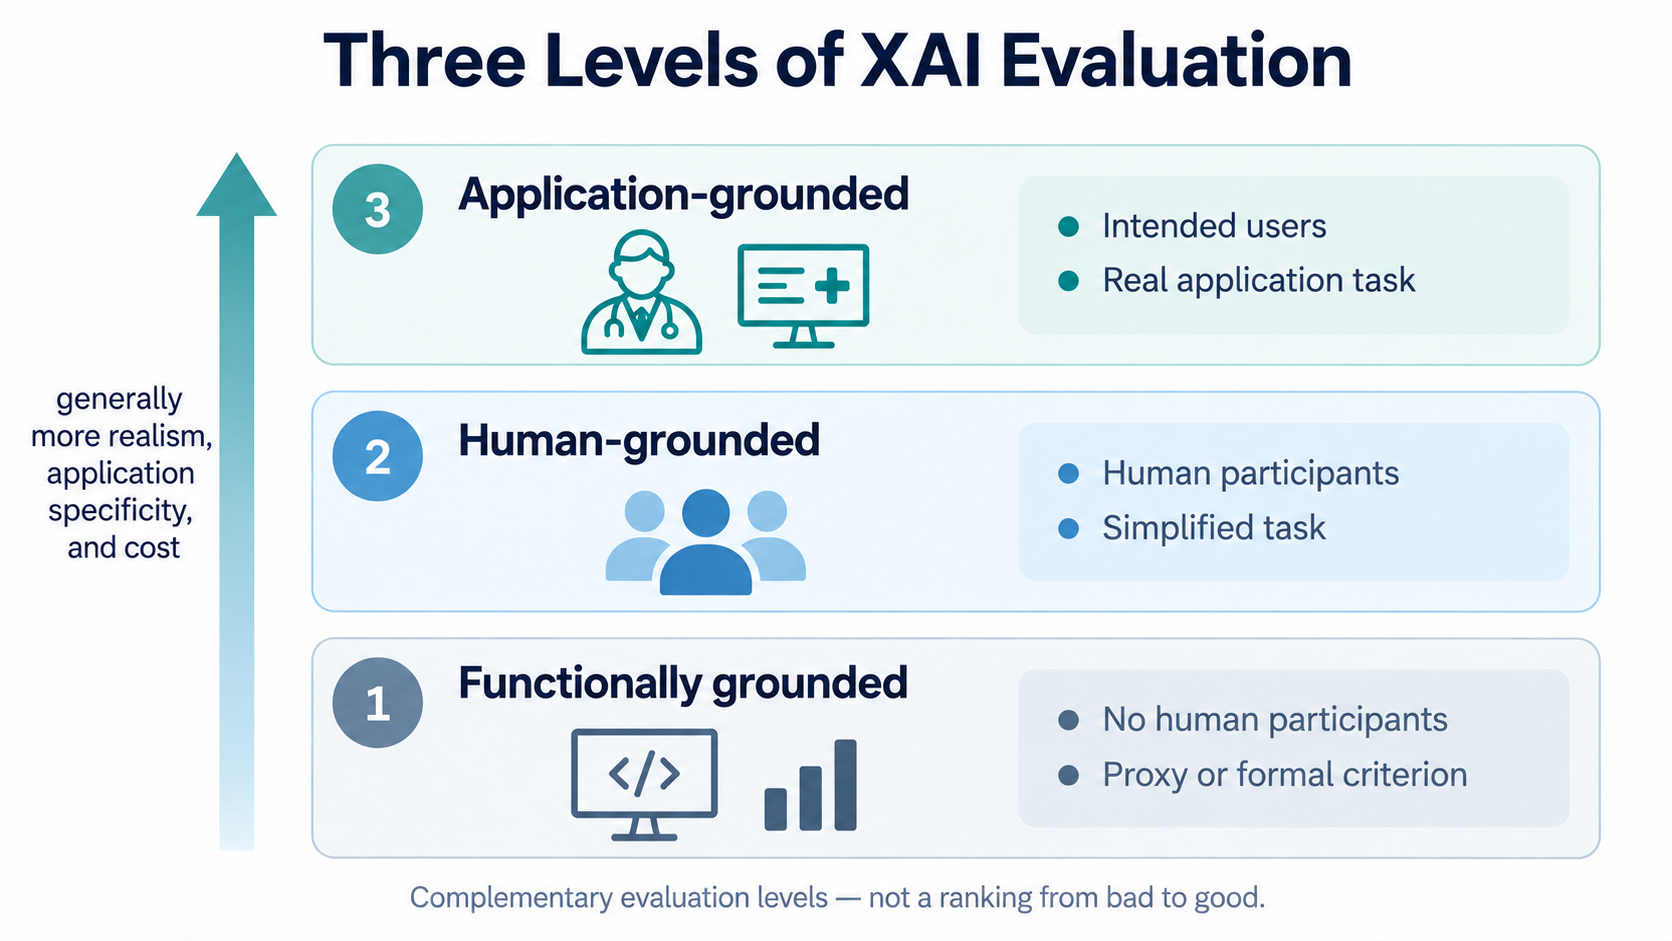

---

## 5.1 Functionally grounded evaluation

### Question

> **Can we evaluate an explanation property without involving human participants?**

Functionally grounded evaluation uses **formal definitions, computational tests, or proxy measures** instead of human-subject experiments.

Examples may include:

- perturbation-based tests;
- stability measures;
- localisation measures;
- sparsity or complexity measures;
- model-sensitivity checks.

### Sensor example — local stability

Suppose an anomaly-detection model receives two almost identical sensor readings:

- temperature = 72.0°C;
- temperature = 72.1°C.

The model produces nearly the same anomaly score for both inputs.

Now compare the explanations.

If one explanation says that **temperature** is the dominant factor, while the other says that **pressure** is the dominant factor, this raises a question about **local explanation stability**.

We can evaluate this computationally by comparing the two explanations using measures such as:

- cosine similarity;
- rank correlation;
- attribution distance.

No human participants are required.

> **This is functionally grounded evaluation because a technical property of the explanation is tested computationally rather than through human judgement.**

However, even if the explanations are stable, this does not tell us whether an engineer will understand them or find them useful.

**Advantages:** efficient, reproducible, and relatively inexpensive.  
**Limitation:** a technical property or proxy may not correspond to what users actually need.

---

## 5.2 Human-grounded evaluation

### Question

> **How do people perform on a simplified task designed to evaluate an explanation?**

Human-grounded evaluation involves **human participants**, but the task is deliberately simplified so that a general property of interpretability can be studied without requiring the full real-world application.

Participants do not necessarily need to be domain experts.

### Loan example — model simulation

Suppose participants are shown:

- a loan-model prediction;
- a SHAP explanation for that prediction.

They are then asked to predict what the model will output for a new applicant.

If participants who receive the explanation are better able to predict the model's behaviour, this provides **behavioural evidence that the explanation improves model simulatability** — that is, the explanation helps people anticipate how the model will behave on new inputs.

This is different from simply asking:

> “Do you like this explanation?”  
> “Does this explanation look clear?”

Those questions measure **subjective perception**.

Model simulation measures whether the explanation actually helps participants **predict model behaviour**.

> **Human-grounded evaluation uses people, but in a simplified task rather than the full application setting.**

**Advantage:** directly evaluates how people interact with or understand explanations in a controlled task.  
**Limitation:** performance on a simplified task may not transfer to the real application.

---

## 5.3 Application-grounded evaluation

### Question

> **How does the explanation affect intended users performing a real or realistic application task?**

Application-grounded evaluation involves the **intended users of the system** performing an application-specific task under realistic conditions.

### Pneumonia example

Suppose radiologists use an AI system that predicts pneumonia from chest X-rays.

We could compare:

- radiologists without AI support;
- radiologists with the AI prediction;
- radiologists with the AI prediction and Grad-CAM explanation.

Possible outcomes include:

- diagnostic accuracy;
- ability to detect model errors;
- decision time;
- appropriate reliance on the AI system.

Here, the question is not simply whether the heatmap looks understandable or convincing.

Instead, we ask:

> **Does the explanation improve relevant aspects of user performance or human–AI interaction in the actual task?**

For example, does it help radiologists:

- make more accurate decisions;
- recognise when the model may be wrong;
- rely on the AI appropriately;
- complete the task more efficiently?

> **Application-grounded evaluation tests explanation usefulness in the intended application context with the intended users.**

**Advantage:** provides highly application-specific evidence about real-world usefulness.  
**Limitation:** such studies are typically more costly, time-consuming, and difficult to control than simplified or purely computational evaluations.

---

## Comparing the three approaches

| Evaluation approach | Human involvement | Typical question |
|---|---|---|
| **Functionally grounded** | none | does the explanation satisfy a defined technical or proxy property? |
| **Human-grounded** | human participants | how do people perform or respond in a simplified interpretability task? |
| **Application-grounded** | intended users | how does the explanation affect performance or human–AI interaction in the real or realistic application? |

> **These approaches are complementary. The appropriate choice depends on the claim, the intended user, and the application context.**

# 6. Property, test, and metric

A common source of confusion in XAI evaluation is treating a **metric** as if it were the property we actually care about.

## Property

> **What do we want to know about the explanation?**

Examples:

- faithfulness;
- stability;
- localisation;
- compactness;
- model sensitivity;
- human utility.

A property is the **evaluation question or quality of interest**.

---

## Test or evaluation design

> **How will we investigate that property?**

Examples:

- perturb important features and observe the model output;
- compare explanations for nearby inputs;
- randomise model parameters and recompute explanations;
- compare a heatmap with a reference region;
- conduct a controlled user study.

The test defines **what experiment we perform**.

---

## Metric

> **How will we quantify the result of the test?**

Examples include:

- cosine similarity;
- rank correlation;
- attribution distance;
- mask overlap;
- Pointing Game accuracy;
- number of features shown;
- task accuracy or decision time.

---

## Examples

| Property | Possible test | Possible metric |
|---|---|---|
| **Faithfulness** | perturb highly attributed features | change in model output |
| **Stability** | compare explanations for nearby inputs with similar model outputs | cosine similarity, rank correlation, attribution distance |
| **Localisation** | compare a spatial explanation with a reference region | Pointing Game, mask overlap, attribution mass inside region |
| **Compactness** | measure explanation size or structure | number of features, rules, tree depth |
| **Model sensitivity** | randomise learned parameters or training labels | similarity between original and randomised explanations |
| **Human utility** | controlled human task | task accuracy, error detection, decision time, appropriate reliance |

Different tests and metrics can be used to evaluate the **same property**.

For example, local stability could be quantified using cosine similarity, rank correlation, or another distance measure depending on the explanation representation.

Likewise, the same metric may not be equally meaningful in every application.

> **Do not start with the metric. Start with the claim, identify the relevant property, and then choose a suitable test and metric.**

# 7. Technical evaluation: the main questions

For this lecture, we organise technical evaluation around six recurring questions.

These are not mandatory tests for every explanation method.  
They represent **different properties that may be relevant depending on the claim being evaluated**.

### 1. Internal consistency

> **Does the explanation satisfy the formal or structural property being checked?**

### 2. Perturbation-based faithfulness evidence

> **Does changing information identified as important affect the model output?**

### 3. Local stability

> **Do nearby inputs with similar model behaviour receive similar explanations?**

### 4. Model sensitivity

> **Does the explanation depend on what the model has learned?**

### 5. Localisation

> **Does a spatial explanation align with a meaningful reference region?**

### 6. Compactness

> **Is the explanation structurally or presentationally concise?**

These questions provide **different kinds of evidence** about explanation quality.

For example:

- an explanation may be internally consistent but unstable;
- it may be spatially well localised but insensitive to model randomisation;
- it may be compact but not useful to a person.

> **Passing one evaluation test does not imply that an explanation is generally good.**

# 8. Formal properties and internal consistency

Some explanation methods have **formal properties by construction**.

These properties can be checked independently of whether the explanation is useful, stable, or meaningful to a person.

### SHAP example

For an additive SHAP explanation, the model output being explained can be written as:

$$
f(x) = \phi_0 + \sum_j \phi_j
$$

where:

- $f(x)$ is the model output in the **output space being explained**;
- $\phi_0$ is the SHAP reference or expected value;
- $\phi_j$ is the contribution assigned to feature $j$.

If the reference value plus the SHAP contributions reconstruct the explained model output up to numerical precision, then the explanation satisfies the expected **additive decomposition**.

### What does this establish?

> **The explanation is internally consistent with the additive property of the SHAP formulation being used.**

This is useful evidence that the explanation has been computed consistently with that formal property.

### What does it not establish?

It does not show that:

- the chosen background or reference data are appropriate;
- the explanation is stable under small changes;
- the attribution represents a causal effect;
- the explanation is understandable or useful to people;
- the explanation is generally faithful in every relevant sense.

> **Formal correctness provides evidence about one specific property; it is not a validation of the explanation as a whole.**

# 9. Perturbation-based evaluation

### Question

> **If an explanation identifies some information as important, does changing that information affect the model output?**

The intuition is simple:

If a feature is important for a particular prediction, then changing or removing that feature should often affect the prediction.

However, the result depends critically on **how the perturbation is performed**.

---

### Loan example

Suppose SHAP assigns a large absolute attribution to **debt-to-income ratio** for one applicant.

We can modify that feature and observe how much the predicted approval probability changes.

But what does it mean to “remove” or “replace” the feature?

Possible choices include:

- setting it to zero;
- replacing it with the mean or median;
- replacing it with another observed value;
- sampling a value conditionally on the other features.

These choices represent **different perturbation designs**.

---

### Why does the perturbation design matter?

Suppose debt-to-income ratio is related to:

- income;
- savings;
- requested loan amount.

Changing only debt-to-income ratio while keeping everything else fixed may create an applicant profile that is unusual or unlikely under the original data distribution.

The observed prediction change therefore reflects both:

1. **the behaviour of the fitted model**;
2. **the perturbation procedure used to modify the input**.

> **Perturbation-based evidence is always conditional on the chosen perturbation design.**

A large prediction change can provide evidence that the model is sensitive to the perturbed information under that design.

It does **not**, by itself, establish a causal effect or universal feature importance.

---

## ROAR — RemOve And Retrain

Hooker et al. (2019) proposed **ROAR — RemOve And Retrain** as a benchmark for evaluating feature-importance rankings.

The basic procedure is:

1. rank features according to their estimated importance;
2. remove or replace the highest-ranked information in both the training and evaluation data;
3. retrain the model on the modified training data;
4. measure how predictive performance changes.

### Why retrain?

In a simple deletion test, the original model may receive perturbed inputs that differ substantially from the data on which it was trained.

ROAR allows the model to **adapt to the modified input representation** through retraining.

If removing information ranked as important causes a larger decrease in predictive performance than removing less-important information, this supports the usefulness of the feature-importance ranking under the ROAR evaluation design.

### Important limitation

ROAR evaluates the performance of a **newly retrained model** after information has been removed.

Therefore:

> **ROAR does not directly test whether an explanation faithfully describes the behaviour of the original fitted model for a particular prediction.**

It answers a related question about whether the information identified by an importance method is useful for predictive performance when the model is retrained without that information.

# 10. Local stability

### Question

> **For nearby inputs with similar model outputs, do the explanations also remain similar?**

Local stability asks whether an explanation changes **reasonably** when the input is changed only slightly.

The key point is that we consider both:

1. how much the **input** changes;
2. how much the **model output** changes.

---

### Sensor example

Suppose an anomaly-detection model receives two nearly identical sensor readings:

> **72.0°C → 72.1°C**

because of ordinary measurement noise.

The model's anomaly score remains almost unchanged.

However, the explanation changes from:

> “temperature is the dominant factor”

to:

> “pressure is the dominant factor”.

This raises a **local stability concern**.

The model behaves almost the same, but the explanation changes substantially.

---

### Conceptually

Let:

- $f(x)$ denote the model output for input $x$;
- $E(f,x)$ denote the explanation for that model and input.

If two nearby inputs produce similar model outputs,

$$
f(x') \approx f(x),
$$

we examine whether their explanations are also similar:

$$
E(f,x') \approx E(f,x).
$$

Possible measures include:

- cosine similarity;
- rank correlation;
- attribution distance.

The appropriate measure depends on how the explanation is represented.

---

### Important qualification

Local stability does **not** mean that explanations should always remain unchanged.

If a small input change causes the model prediction to change substantially — for example, because the input crosses an important decision boundary — then a large explanation change may be appropriate.

> **Explanation stability should therefore be interpreted relative to both the input change and the model's behaviour.**

# 11. Model sensitivity and randomisation

### Question

> **Does the explanation depend on what the model has learned?**

Adebayo et al. (2018) introduced **sanity checks for saliency methods**, originally studying image-classification explanations.

The basic idea is simple:

> If an explanation is intended to reflect learned model behaviour, then substantially disrupting what the model has learned should usually affect the explanation.

---

## Parameter randomisation

Progressively randomise the learned model parameters and recompute the explanation.

If the explanation changes substantially as the parameters are randomised, this suggests that the explanation is sensitive to the fitted model.

If it remains very similar, that raises a concern that the explanation may depend strongly on factors other than the learned parameters.

---

## Data randomisation

Randomise the training labels, retrain the model, and recompute the explanations.

This tests whether the explanation responds to information learned from the relationship between the training inputs and the target labels.

---

### Pneumonia example

Suppose a saliency-style heatmap for a pneumonia classifier remains visually very similar after substantial model-parameter randomisation.

This raises the possibility that the explanation is responding strongly to:

- generic image structure;
- architectural properties;

rather than primarily to the learned decision behaviour of the fitted model.

> **If an explanation is intended to describe learned model behaviour, destroying learned information should generally affect the explanation.**

### Important qualification

Randomisation tests are **diagnostic checks**.

They do not provide a universal pass/fail certificate for an explanation method, and their interpretation depends on:

- which parameters are randomised;
- how much of the model is randomised;
- which explanation method is used;
- how explanation similarity is measured.

> **The test asks whether the explanation is sensitive to learned model information — not whether the explanation is universally “good” or “bad”.**

# 12. Localisation

### Question

> **Does a spatial explanation align with an appropriate reference region?**

Localisation-based evaluation compares a spatial explanation with a **reference region** that is considered relevant for the task.

### Pneumonia example

Suppose a radiologist marks a region of a chest X-ray that is relevant to the pneumonia assessment.

The Grad-CAM heatmap overlaps strongly with that region.

Possible localisation measures include:

- Pointing Game;
- segmentation-mask overlap;
- bounding-box overlap;
- fraction of attribution mass inside the reference region.

### What can we conclude?

> **The explanation shows spatial agreement with the chosen reference region.**

This provides evidence about **localisation**.

### What can we not conclude?

The result does not by itself show that:

- the classifier relied only on that region;
- the explanation is fully faithful to the fitted model;
- the highlighted region has a causal effect on the prediction;
- the explanation is stable under small input changes.

The radiologist's annotation is a **spatial reference for evaluation**. It is not a direct observation of the model's internal decision process.

> **Localisation evaluates spatial agreement with a reference region; it does not by itself establish model faithfulness.**

# 13. Complexity and compactness

### Question

> **How concise or structurally simple is the explanation or its presentation?**

Possible measures include:

- number of features shown;
- number of rules;
- tree depth;
- attribution concentration;
- explanation length.

### Loan example

Suppose a SHAP explanation contains contributions from many features.

An interface might display only the four largest contributions instead of showing all twenty.

The four-feature display is **more compact**, but this is mainly a property of the **presentation**.

The underlying SHAP explanation may still contain contributions from many features.

A more compact presentation may be easier to inspect, but it can also hide information that is relevant to the model prediction.

> **Compactness is not evidence of faithfulness or human understanding.**

Similarly, a structurally simple explanation is not automatically easy for a person to understand.

If the claim is:

> **“Users understand the shorter explanation better,”**

then that claim requires **human evaluation**.

> **Complexity and compactness describe structural or presentational simplicity; they do not by themselves establish explanation quality.**

# 14. Sensitivity to explainer configuration

The fitted model is not the only source of variation in an explanation.

The same model and the same input can produce different explanations when the **explainer configuration** changes.

| Method | Important configuration choice |
|---|---|
| Integrated Gradients | baseline |
| SHAP | background/reference data |
| LIME | perturbation sampling, random seed, kernel width |
| Grad-CAM | target convolutional layer |

These choices are part of how the explanation itself is defined.

---

### SHAP example

Keep fixed:

- the loan model;
- the applicant.

Change only:

- the background sample used by interventional TreeSHAP.

If the SHAP values change, the fitted model has not changed.

The explanation changes because the **reference used by the explainer has changed**.

This does not automatically mean that SHAP is incorrect.

Instead, it shows that the explanation is **conditional on the selected background/reference data**.

### What does this tell us?

A sensitivity analysis can ask:

> **Do reasonable changes in the explainer configuration lead to similar qualitative conclusions?**

For example, do the same features remain highly ranked when different reasonable background samples are used?

If the explanation changes substantially across reasonable choices, then the interpretation should acknowledge that sensitivity.

> **Explainer configuration is part of the experimental setup and should be reported clearly. When configuration choices may materially affect the result, they should also be sensitivity-tested.**

# 15. Human-centred evaluation

Technical evaluation asks whether an explanation satisfies computational properties such as faithfulness, stability, or model sensitivity.

Human-centred evaluation asks:

> **What happens when people actually see and use the explanation?**

Different human-centred outcomes should be kept separate.

Hoffman et al. (2023) discuss several relevant aspects, including:

- explanation goodness;
- explanation satisfaction;
- mental models;
- trust and reliance;
- human–AI performance.

Kim et al. (2024) reviewed **73 papers** containing XAI user studies and identified **30 evaluated components**, grouped into three broad dimensions:

1. **in-context explanation quality**;
2. **human–AI interaction**;
3. **human–AI performance**.

Their review focused on **decision-support systems using tabular or textual input data** and excluded image-based systems, so its empirical scope should not automatically be generalised to every XAI modality.

> **These outcomes are related, but they are not interchangeable.**

---

## 15.1 Subjective outcomes

Examples:

- “The explanation is clear.”
- “I find the explanation useful.”
- “I trust the explanation.”

These tell us what users **report or perceive**.

They are valuable, but they do not by themselves show that the explanation improves understanding or task performance.

---

## 15.2 Understanding and model simulation

A stronger behavioural question is whether the explanation helps a person **anticipate how the model will behave**.

### Loan example — model simulation

Can a person use the explanation to predict what the model will output for a new applicant?

Hase and Bansal (2020) evaluated this kind of **model simulatability**.

They found that subjective ratings of explanations were **not reliable predictors of measured helpfulness** on the simulation task.

Therefore:

> **Users liking an explanation is not the same as the explanation helping them predict model behaviour.**

---

## 15.3 Human–AI interaction

Possible questions include:

- Does the user rely on the AI when it is appropriate?
- Can the user recognise when the AI may be wrong?
- Does the explanation encourage over-reliance?
- Does it lead to unnecessary under-reliance?

The goal is not automatically **more trust**.

The goal is often:

> **appropriate reliance**

---

## 15.4 Human–AI performance

### Pneumonia example

If the claim is:

> **“Grad-CAM helps radiologists make better decisions.”**

then suitable outcomes may include:

- diagnostic accuracy;
- ability to detect model errors;
- decision time;
- appropriate reliance on the AI system.

A questionnaire asking whether radiologists like or understand the heatmap is not sufficient to support a claim about improved decision-making.

> **If the claim is behavioural, the evaluation should include a behavioural measure.**

# 16. Worked case — evaluating one TreeSHAP explanation

Now we apply the evaluation ideas to one **synthetic loan applicant**.

The Random Forest predicts an approval probability of:

> **0.598**

The SHAP reference value is approximately:

> **0.324**

Before evaluating the explanation, remember what a SHAP value means.

## Reading the SHAP explanation

For this explained approval probability:

- a **positive SHAP value** pushes the prediction upward relative to the reference value;
- a **negative SHAP value** pushes it downward relative to the reference value;
- the **absolute magnitude** tells us how large that contribution is within this explanation.

A positive SHAP value does **not** mean that a feature is:

- good;
- desirable;
- beneficial;
- causal.

It is simply a contribution to the model output relative to the chosen SHAP reference.

---

# Check 1 — Does the explanation reconstruct the model output?

### What are we checking?

We first check the **additive SHAP property**.

The reference value plus all SHAP contributions should reproduce the model output being explained.

Conceptually:

$$
\text{reference value} + \sum_j \phi_j
=
\text{model output}
$$

### What do we observe?

The SHAP reconstruction gives approximately:

> **0.598**

which matches the model's predicted approval probability.

### What can we conclude?

> **The SHAP explanation is internally consistent with the additive decomposition for this explained output.**

### What can we not conclude?

This does not tell us whether the explanation is:

- generally faithful;
- stable;
- causal;
- useful to a person.

> **Reconstruction checks mathematical consistency, not overall explanation quality.**

---

# Check 2 — Do highly ranked SHAP features affect the prediction?

### What are we checking?

Now we test a more empirical question.

SHAP ranks features by the magnitude of their local contribution.

If the highest-ranked features are important to this prediction, then replacing them early should often change the model output more quickly than replacing features in a random order.

### What do we do?

1. Rank the features by absolute SHAP value.
2. Replace them one at a time with their training-set median.
3. After each replacement, measure the **absolute change in predicted approval probability**.
4. Compare this with many random feature orders.

### What should we look at?

Focus on the **early part of the curve**.

Why?

Because the question is whether the highest-ranked features disturb the prediction **earlier** than an arbitrary ordering.

### What can we conclude?

If the SHAP ordering produces larger early changes than the random-order baseline:

> **This provides perturbation-based evidence relevant to local faithfulness under this median-replacement design.**

### Why is the conclusion narrow?

Because the result depends on the chosen perturbation rule.

Replacing a feature with the training median is only one possible way of changing the input.

So this result does not establish:

- causality;
- global feature importance;
- universal faithfulness.

---

## Two useful observations about the perturbation curve

### Why do the curves meet at the end?

After every feature has been replaced by its median, the final input is the same regardless of the replacement order.

Therefore the curves must end at the same point.

### Why can the curve move up and down?

Replacing another feature can:

- reinforce an earlier change;
- compensate for an earlier change;
- interact with other features.

So the distance from the original prediction does not have to increase monotonically.

---

# Check 3 — Does the explanation depend strongly on the SHAP background sample?

### What are we checking?

Interventional TreeSHAP uses background data to define the reference against which contributions are calculated.

So we ask:

> **If we change only the background sample, does the explanation change substantially?**

### What stays fixed?

- the fitted Random Forest;
- the applicant.

### What changes?

Only the TreeSHAP background sample.

### What do we observe?

For two different background samples:

- reference value: **0.324 vs 0.310**;
- cosine similarity of signed SHAP vectors: **0.981**;
- Spearman rank correlation of absolute SHAP magnitudes: **0.905**.

### How do we interpret this?

The two explanations are **very similar overall**.

The high cosine similarity indicates that the signed attribution vectors have very similar overall direction.

The high Spearman correlation indicates that the feature rankings by absolute SHAP magnitude are also similar.

However:

> **A cosine similarity of 0.981 does not mean the explanations are 98.1% identical.**

### What can we conclude?

> **These two background samples produce similar explanations for this applicant.**

### What can we not conclude?

We cannot say that SHAP is generally robust to background choice.

We tested only:

- two background samples;
- from the same training data;
- for one applicant.

A stronger sensitivity analysis would compare:

- many background samples;
- different background sizes;
- possibly different reference populations.

---

# What did the three checks tell us?

| Check | Question | Evidence |
|---|---|---|
| **1. Reconstruction** | is the additive SHAP decomposition internally consistent? | yes |
| **2. Perturbation** | do highly ranked features affect the model output early under median replacement? | perturbation-based evidence |
| **3. Background sensitivity** | do two reasonable background samples give similar explanations? | yes, for these two samples |

The important lesson is:

> **No single check tells us that the explanation is simply “good”.**

Each test answers a different question.


# 17. Putting the evaluation together

We can now connect different explanation claims to the kinds of evidence needed to evaluate them.

| Claim | Relevant property | Suitable test |
|---|---|---|
| “Highly attributed SHAP features affect this prediction under perturbation.” | local faithfulness | perturbation-based evaluation |
| “The sensor explanation is stable.” | local stability | compare nearby inputs with similar model outputs |
| “The heatmap depends on learned model information.” | model sensitivity | randomisation test |
| “The heatmap aligns with a relevant spatial region.” | localisation | comparison with a spatial reference |
| “The explanation is compact.” | compactness | complexity or sparsity measure |
| “The explanation helps radiologists perform the task.” | human utility / performance | controlled human study |

The important point is that each test answers a **specific question**.

A successful result should therefore lead to a **scoped conclusion**, not a general statement that the explanation is simply “good”.

---

## The workflow

> ## **Claim → property → test → evidence → scoped conclusion**

For every evaluation, ask:

1. **What exactly is the claim?**
2. **What property does that claim depend on?**
3. **What test is appropriate for that property?**
4. **What evidence did the test produce?**
5. **What conclusion is justified by that evidence?**
6. **What conclusion is not justified?**

### Example

Suppose a Grad-CAM heatmap overlaps strongly with a radiologist-defined reference region.

Then:

- **Claim:** the heatmap aligns with the reference region;
- **Property:** localisation;
- **Test:** compare the heatmap with the reference region;
- **Evidence:** high spatial overlap;
- **Scoped conclusion:** the explanation shows strong spatial agreement with this reference;
- **Not justified:** the model relied only on that region, or the explanation is fully faithful.

> **The strength and scope of the conclusion should not exceed the strength and scope of the evidence.**

# 18. Common evaluation mistakes

## Mistake 1 — choosing a metric before defining the claim

A metric is only useful if it measures a property that is relevant to the claim being evaluated.

> **Start with the claim, not the metric.**

---

## Mistake 2 — treating plausibility as faithfulness

An explanation may look reasonable or familiar to a person while still poorly reflecting the behaviour of the fitted model.

> **Human plausibility is not evidence of model faithfulness.**

---

## Mistake 3 — interpreting proxy measures too strongly

A technical measure often provides evidence about only one property.

For example:

- compactness → does not automatically mean **easy to understand**;
- localisation → does not automatically mean **the model relied on this region**;
- satisfaction → does not automatically mean **better decisions**.

These stronger conclusions require additional evidence.

> **Do not claim more than the measure actually supports.**

---

## Mistake 4 — ignoring the evaluation design

Evaluation results depend on how the test is constructed.

For example:

- perturbation results depend on the perturbation procedure;
- SHAP explanations depend on the chosen background or reference data;
- stability results depend on how nearby inputs and explanation similarity are defined;
- localisation results depend on the chosen spatial reference.

> **Evaluation evidence is conditional on the evaluation design.**

---

## Mistake 5 — searching for one universal XAI score

Explanation quality is **multi-dimensional**.

An explanation may perform well on one property and poorly on another.

Different properties therefore require different tests and different evidence.

> **There is no universal metric that proves an explanation is simply “good”.**

# 19. Challenges in XAI evaluation

Evaluating explanations remains difficult because several sources of uncertainty and variation are involved.

### Conceptual challenges

- terminology is not fully standardised;
- terms such as *faithfulness*, *fidelity*, *robustness*, and *stability* may be used differently across papers;
- explanation quality is multi-dimensional;
- desirable properties may conflict with one another.

### Methodological challenges

- proxy measures may not capture what users actually need;
- results depend on the evaluation design;
- explanations may depend strongly on method and configuration choices;
- different tests may provide different kinds of evidence.

### Human and contextual challenges

- human studies can be expensive and application-specific;
- different users may require different kinds of explanations;
- explanation usefulness may depend on the task and deployment context;
- findings from one application may not transfer directly to another.

These challenges do not make evaluation less important.

They make **explicit evaluation design and careful interpretation** more important.

> **State the claim, the evaluation assumptions, the evidence obtained, and the limits of the conclusion.**

# 20. XAI evaluation within Trustworthy AI

Explainability can contribute to several goals associated with Trustworthy AI, including:

- transparency;
- debugging;
- failure analysis;
- human oversight;
- auditing;
- accountability.

However, explainability is only **one part of a broader trustworthiness assessment**.

A trustworthy AI system may require evidence at several levels:

| Level | Example concerns |
|---|---|
| **Model** | predictive performance, calibration, robustness, fairness |
| **Explanation** | faithfulness, stability, localisation, compactness |
| **Human–AI interaction** | understanding, reliance, oversight, decision quality |
| **System and context** | safety, privacy, accountability, governance |

These levels are related, but evidence at one level does not automatically establish trustworthiness at the others.

---

### Loan example

Suppose SHAP provides a highly faithful explanation of a loan model.

If the underlying model is systematically unfair toward a particular group, then the explanation may accurately reveal the behaviour of an **unfair model**.

> **A faithful explanation does not make the underlying model fair.**

---

### Pneumonia example

Suppose a Grad-CAM explanation produces a convincing and well-localised heatmap.

The classifier may still be:

- poorly calibrated;
- insufficiently robust;
- unsafe under distribution shift;
- unsuitable for clinical deployment.

> **A convincing explanation does not make an unsafe model trustworthy.**

---

## The broader lesson

XAI evaluation asks whether explanation-related claims are supported by evidence.

Trustworthy AI asks a broader question:

> **Is there sufficient evidence to justify relying on the model, the explanation, the human–AI interaction, and the surrounding system in this context?**

Therefore:

> **A good explanation does not repair a bad model or a poorly governed system.**

And equally:

> **Evaluating explanations is one important component of Trustworthy AI — not a substitute for evaluating the rest of the system.**

# 21. Breakout discussion

A hospital is testing an AI system that predicts **pneumonia from chest X-rays**.

Grad-CAM produces a heatmap for each prediction.

The researchers observe that:

- heatmaps often overlap with regions radiologists mark as relevant;
- perturbing highly highlighted regions often changes the model prediction;
- similar X-rays with similar model outputs sometimes produce substantially different heatmaps;
- radiologists report that the heatmaps are useful.

The researchers want to claim:

> **“Grad-CAM provides reliable explanations that help radiologists make better decisions.”**

## Discuss

1. **What does the spatial overlap support?**

2. **What does the perturbation result support?**

3. **Which observation raises a local-stability concern?**

4. **What does “radiologists report that the heatmaps are useful” actually establish?**

5. **What evidence is still missing before claiming that the explanations improve radiologists' decisions?**

6. **Is the word “reliable” justified by the current evidence? Why or why not?**

---

## New evidence

After 5–6 minutes, reveal:

> **After substantial model-parameter randomisation, the heatmaps remain visually very similar.**

Now discuss:

1. **What property is this test evaluating?**
2. **What concern does this result raise?**
3. **Does it invalidate the localisation result?**
4. **Does it invalidate the perturbation result?**
5. **How should the overall claim now be narrowed?**

---

## Final task

Write one statement that is **fully supported by the available evidence**.

Use the structure:

> **The evidence supports __________, but does not yet establish __________.**

# 22. Summary

The purpose of XAI evaluation is not to decide whether an explanation is simply **“good” or “bad.”**

The central question is:

> **Which claims about the explanation are actually supported by evidence?**

## Key lessons

### Why evaluate explanations?

Because explanations can be:

- convincing but poorly reflect model behaviour;
- unstable;
- sensitive to explainer configuration;
- formally correct but unhelpful to users.

### What makes an explanation good?

There is no single universal answer.

Explanation quality is **multi-dimensional** and depends on:

- the claim being made;
- the property being evaluated;
- the intended user;
- the task;
- the application context.

### What kinds of evidence can we use?

Depending on the claim, evaluation may involve:

- formal or internal-consistency checks;
- perturbation-based tests;
- local-stability tests;
- model-randomisation tests;
- localisation measures;
- complexity or compactness measures;
- human-centred studies.

Different tests answer **different questions**.

### The main rule

> **Use evidence that matches the property you are claiming.**

And interpret that evidence within the scope of the evaluation.

For example:

- localisation does not establish complete model faithfulness;
- additive reconstruction does not establish usefulness;
- subjective preference does not establish improved task performance;
- perturbation evidence is conditional on the perturbation design;
- configuration sensitivity does not automatically mean that an explanation method is incorrect.

---

## Final workflow

> ## **Claim → property → test → evidence → scoped conclusion**

When reading an XAI paper or evaluating your own explanation, ask:

> **What exactly has been demonstrated here — and what has not?**

# Week 3 exercises

The Week 3 practical exercises use **Captum** across three data modalities.

### Exercise 1 — Time-series data

### Exercise 2 — Text data

### Exercise 3 — Image data

### Data folder

```text
Week3/data/
```

> **Exercise focus:** Generate explanations, identify what each explanation claims to show, and consider which evaluation property would provide appropriate evidence for that claim.

# References

- Adebayo, J., Gilmer, J., Muelly, M., Goodfellow, I., Hardt, M., & Kim, B. (2018). *Sanity Checks for Saliency Maps.* NeurIPS.

- Alvarez-Melis, D., & Jaakkola, T. S. (2018). *On the Robustness of Interpretability Methods.* Workshop on Human Interpretability in Machine Learning.

- Doshi-Velez, F., & Kim, B. (2017). *Towards a Rigorous Science of Interpretable Machine Learning.* arXiv:1702.08608.

- Hase, P., & Bansal, M. (2020). *Evaluating Explainable AI: Which Algorithmic Explanations Help Users Predict Model Behavior?* ACL.

- Hoffman, R. R., Mueller, S. T., Klein, G., & Litman, J. (2023). *Measures for explainable AI: Explanation goodness, user satisfaction, mental models, curiosity, trust, and human-AI performance.* Frontiers in Computer Science, 5, 1096257.

- Hooker, S., Erhan, D., Kindermans, P.-J., & Kim, B. (2019). *A Benchmark for Interpretability Methods in Deep Neural Networks.* NeurIPS.

- Kim, J., Maathuis, H., & Sent, D. (2024). *Human-centered evaluation of explainable AI applications: a systematic review.* Frontiers in Artificial Intelligence, 7, 1456486.

- Lundberg, S. M., & Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions.* NeurIPS.

- Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., Katz, R., Himmelfarb, J., Bansal, N., & Lee, S.-I. (2020). *From local explanations to global understanding with explainable AI for trees.* Nature Machine Intelligence, 2, 56–67.

- Nauta, M., Trienes, J., Pathak, S., Nguyen, E., Peters, M., Schmitt, Y., Schlötterer, J., van Keulen, M., & Seifert, C. (2023). *From Anecdotal Evidence to Quantitative Evaluation Methods: A Systematic Review on Evaluating Explainable AI.* ACM Computing Surveys, 55(13s), Article 295.

- Ribeiro, M. T., Singh, S., & Guestrin, C. (2016). *“Why Should I Trust You?”: Explaining the Predictions of Any Classifier.* KDD.

- Selvaraju, R. R., Cogswell, M., Das, A., Vedantam, R., Parikh, D., & Batra, D. (2017). *Grad-CAM: Visual Explanations from Deep Networks via Gradient-Based Localization.* ICCV.

- Sokol, K., & Vogt, J. E. (2024). *What Does Evaluation of Explainable Artificial Intelligence Actually Tell Us? A Case for Compositional and Contextual Validation of XAI Building Blocks.* CHI Extended Abstracts.

- Sundararajan, M., Taly, A., & Yan, Q. (2017). *Axiomatic Attribution for Deep Networks.* ICML.